# TP 5 - Concevoir un schéma en étoile pour la BI
### Spaceship Titanic · Modélisation décisionnelle · EPSI

**Version : correction enseignant · Durée cible : 60 minutes · TP guidé**

**Question métier :** qui consomme quels services à bord du vaisseau, quand, où et pour quel montant ?

**Objectifs**
1. Définir le **grain** de la table de faits et distinguer faits/dimensions.
2. Construire **trois dimensions** et **une table de faits** dans Gold.
3. Réutiliser la **dimension calendrier du TP4** sans la recréer.
4. Répondre à **quatre questions métier en SQL** et vérifier les totaux.

**IMPORTANT — données synthétiques :** le fichier supplémentaire répartit les
montants cumulés de `RoomService`, `FoodCourt` et `Spa` en transactions fictives.
**Les dates, les lieux et les transactions individuelles sont inventés** ;
seuls les totaux par passager et service sont conservés. Ne pas interpréter
les résultats temporels ou géographiques comme des faits observés.

**Pas de remise à zéro :** n'exécutez **aucun** autre TP. Ce notebook réutilise
les tables Delta produites précédemment et ne modifie pas les tables TP3/TP4.

## 0. Préparer le TP

Dans **Workspace**, importez ce notebook. Dans **Catalog Explorer**, déposez
`spaceship_service_transactions.csv` dans le volume du TP3 :
`spaceship.landing.sources` (ou `workspace.landing.sources`).

**Prérequis :**
- `silver.passengers_enriched` du TP3 (4 000 passagers) ;
- `gold.dim_calendar_2025` du TP4 (365 dates).

Exécutez la cellule. Si les tables sont absentes, **arrêtez-vous** : il ne faut
pas relancer ici les traitements des TP précédents.

In [0]:
from pyspark.sql import functions as F

CATALOGUE = "spaceship"  # remplacer par "workspace" si nécessaire

PASSENGERS = f"{CATALOGUE}.silver.passengers_enriched"
CALENDAR = f"{CATALOGUE}.gold.dim_calendar_2025"
BRONZE = f"{CATALOGUE}.bronze.service_transactions"
SILVER = f"{CATALOGUE}.silver.service_transactions"
DIM_PASSENGER = f"{CATALOGUE}.gold.dim_passenger"
DIM_SERVICE = f"{CATALOGUE}.gold.dim_service"
DIM_LOCATION = f"{CATALOGUE}.gold.dim_location"
FACT = f"{CATALOGUE}.gold.fact_service_usage"

VOLUME = f"/Volumes/{CATALOGUE}/landing/sources"
FICHIER = "spaceship_service_transactions.csv"
CHEMIN_CSV = f"{VOLUME}/{FICHIER}"

for table in (PASSENGERS, CALENDAR):
    if not spark.catalog.tableExists(table):
        raise ValueError(f"Prérequis absent : {table}. Consultez le TP3 / TP4.")

assert spark.table(PASSENGERS).count() == 4000, "Nombre de passagers inattendu"
assert spark.table(PASSENGERS).select("PassengerId").distinct().count() == 4000
assert spark.table(CALENDAR).count() == 365, "Calendrier 2025 incomplet"

if FICHIER not in {f.name for f in dbutils.fs.ls(VOLUME)}:
    raise FileNotFoundError(f"Importez le CSV dans {VOLUME} : {FICHIER}")

print("Prérequis vérifiés. Nouveau fichier trouvé :", CHEMIN_CSV)

Prérequis vérifiés. Nouveau fichier trouvé : /Volumes/spaceship/landing/sources/spaceship_service_transactions.csv


## 1. Charger la nouvelle source en Bronze et Silver

**À observer :** le CSV est une nouvelle source opérationnelle *simulée*,
indépendante des deux CSV historiques de passagers. On la dépose en Bronze
**sans modifier ses valeurs**, puis on convertit les types en Silver.

**Démonstration fournie :** aucune transformation avancée à programmer.
À la réexécution, Bronze est conservée ; seules les tables de ce TP en
Silver et Gold sont reconstruites.

In [0]:
COLONNES = [
    "transaction_id", "PassengerId", "transaction_date", "service_code",
    "service_name", "service_family", "location_code", "location_name",
    "location_deck", "location_zone", "amount",
]

if not spark.catalog.tableExists(BRONZE):
    raw = (spark.read.option("header", True).option("inferSchema", False)
           .csv(CHEMIN_CSV))
    assert raw.columns == COLONNES, "En-têtes CSV inattendus"
    (raw.withColumn("_source_file", F.lit(FICHIER))
        .withColumn("_ingested_at", F.current_timestamp())
        .write.format("delta").mode("ignore").saveAsTable(BRONZE))
    print("Bronze créée :", BRONZE)
else:
    print("Bronze existante conservée :", BRONZE)

# Cellule guidée : types DATE / DECIMAL et conservation des métadonnées d'origine.
transactions = (spark.table(BRONZE)
    .select(*COLONNES, "_source_file", "_ingested_at")
    .withColumn("transaction_date", F.to_date("transaction_date", "yyyy-MM-dd"))
    .withColumn("amount", F.col("amount").cast("decimal(14,2)")))

# Contrôles bloquants avant publication.
champs_obligatoires = ("transaction_id", "PassengerId", "transaction_date",
                      "service_code", "location_code", "amount")
condition_invalide = (F.col("amount") <= 0) | (F.year("transaction_date") != 2025)
for champ in champs_obligatoires:
    condition_invalide = condition_invalide | F.col(champ).isNull()
audit_source = transactions.agg(
    F.count("*").alias("lignes"),
    F.countDistinct("transaction_id").alias("ids_distincts"),
    F.sum(F.when(condition_invalide, 1).otherwise(0)).alias("lignes_invalides"),
).first()
assert audit_source["lignes"] == 9260, "Mauvais CSV de transactions"
assert audit_source["ids_distincts"] == 9260, "Identifiants de transactions non uniques"
assert audit_source["lignes_invalides"] == 0, "Lignes invalides (NULL/date/montant)"

# Un code de service / lieu doit correspondre à une description unique.
for code, descriptions in (
    ("service_code", ["service_name", "service_family"]),
    ("location_code", ["location_name", "location_deck", "location_zone"]),
):
    conflits = (transactions.select(code, *descriptions).distinct()
                .groupBy(code).count().filter("count > 1").count())
    assert conflits == 0, f"Descriptions incompatibles pour {code}"

assert transactions.select("PassengerId").distinct().join(
    spark.table(PASSENGERS).select("PassengerId"), "PassengerId", "left_anti"
).count() == 0, "Transaction rattachée à un passager inconnu"

(transactions.write.format("delta").mode("overwrite")
    .option("overwriteSchema", "true").saveAsTable(SILVER))

print("Silver publiée :", SILVER)
display(spark.table(SILVER).select(*COLONNES).limit(5))

Bronze créée : spaceship.bronze.service_transactions
Silver publiée : spaceship.silver.service_transactions


transaction_id,PassengerId,transaction_date,service_code,service_name,service_family,location_code,location_name,location_deck,location_zone,amount
TRX0000001,0007_01,2025-07-06,FOOD,Food Court,Restauration,FOOD_ATRIUM,Food Court Atrium,C,Tribord,10.00
TRX0000002,0007_01,2025-07-09,FOOD,Food Court,Restauration,FOOD_ATRIUM,Food Court Atrium,C,Tribord,58.00
TRX0000003,0007_01,2025-07-06,FOOD,Food Court,Restauration,FOOD_ATRIUM,Food Court Atrium,C,Tribord,401.00
TRX0000004,0007_01,2025-07-06,FOOD,Food Court,Restauration,FOOD_PROMENADE,Food Court Promenade,D,Bâbord,316.00
TRX0000005,0007_01,2025-07-09,SPA,Spa,Bien-être,SPA_CENTRAL,Spa Central,B,Bâbord,4.00


## 2. Identifier le processus métier et le grain

**Question 1 :** que représente **une ligne** de `silver.service_transactions` ?

**Réponse :** une transaction synthétique (montant d'un service consommé
par un passager, à une date et dans un lieu). La clé `transaction_id`
identifie une ligne. Ce n'est **pas** une ligne par passager ou par jour.

**Question 2 :** quels sont les axes d'analyse ?

- **Qui ?** le passager et ses attributs (planète, VIP, etc.).
- **Quoi ?** le type de service.
- **Quand ?** la dimension calendrier déjà créée au TP4.
- **Où ?** le lieu de consommation / livraison à bord.
- **Combien ?** la mesure additive `amount`.

**Précision :** le nombre de transactions représente des lignes de
consommation simulées ; ce n'est pas une fréquentation réellement observée.

## 3. Construire les dimensions Gold

**Démonstration guidée.** On définit trois dimensions :
`dim_passenger`, `dim_service`, `dim_location`. Chacune possède une
**clé substitut** (`*_key`) et un identifiant métier (`PassengerId`,
`service_code` ou `location_code`).

**Exercice 1 :** repérez dans le SQL la clé métier, la clé substitut
et deux attributs descriptifs de chaque dimension.

**Remarque :** `ROW_NUMBER` est une simplification pour reconstruire
intégralement de petites dimensions fixes. Ce n'est pas une stratégie
d'historisation SCD2 ni un système de clés stables en production.

In [0]:
spark.sql(f"""
CREATE OR REPLACE TABLE {DIM_PASSENGER} USING DELTA AS
SELECT
    ROW_NUMBER() OVER (ORDER BY PassengerId) AS passenger_key,
    PassengerId AS passenger_id,
    HomePlanet AS home_planet,
    Destination AS destination,
    CAST(VIP AS BOOLEAN) AS is_vip,
    CAST(CryoSleep AS BOOLEAN) AS cryo_sleep,
    CAST(Age AS DOUBLE) AS age,
    gender,
    CAST(HomePlanet_imputed AS BOOLEAN) AS homeplanet_imputed,
    CAST(RoomService_missing AS BOOLEAN) AS roomservice_was_missing
FROM {PASSENGERS}
""")

spark.sql(f"""
CREATE OR REPLACE TABLE {DIM_SERVICE} USING DELTA AS
SELECT
    ROW_NUMBER() OVER (ORDER BY service_code) AS service_key,
    service_code,
    service_name,
    service_family
FROM (
    SELECT DISTINCT service_code, service_name, service_family
    FROM {SILVER}
)
""")

spark.sql(f"""
CREATE OR REPLACE TABLE {DIM_LOCATION} USING DELTA AS
SELECT
    ROW_NUMBER() OVER (ORDER BY location_code) AS location_key,
    location_code,
    location_name,
    location_deck,
    location_zone
FROM (
    SELECT DISTINCT location_code, location_name, location_deck, location_zone
    FROM {SILVER}
)
""")

for table, attendu in ((DIM_PASSENGER, 4000), (DIM_SERVICE, 3), (DIM_LOCATION, 18)):
    obtenu = spark.table(table).count()
    assert obtenu == attendu, f"{table} : {obtenu} lignes au lieu de {attendu}"
    print(table, "—", obtenu, "lignes")

display(spark.table(DIM_SERVICE).orderBy("service_key"))

spaceship.gold.dim_passenger — 4000 lignes
spaceship.gold.dim_service — 3 lignes
spaceship.gold.dim_location — 18 lignes


service_key,service_code,service_name,service_family
1,FOOD,Food Court,Restauration
2,ROOM,Room Service,Restauration
3,SPA,Spa,Bien-être


**Une quatrième dimension existe déjà :** `gold.dim_calendar_2025`.
Elle représente 365 dates, identifiées par `date_key` (par exemple
`20250310`). **Ne la recréez pas.**

**Discussion :** pourquoi la planète d'origine et le statut VIP sont-ils
conservés dans `dim_passenger`, plutôt que de créer une table pour
chaque attribut ? (Dans une étoile, une dimension regroupe souvent
les attributs descriptifs utiles pour éviter des jointures supplémentaires.)

## 4. Construire la table de faits

**Exercice 2 :** pour chaque transaction Silver, récupérer les **quatre
clés étrangères** (passager, service, lieu, date), puis conserver
`transaction_id` et `amount`.

Le code corrigé est fourni. Observez les `JOIN` : on utilise les
**identifiants métier de Silver** pour retrouver les **clés de Gold**.
Les dates sont reliées via `calendar_date`, et non en inventant des
identifiants de calendrier.

In [0]:
spark.sql(f"""
CREATE OR REPLACE TABLE {FACT} USING DELTA AS
SELECT
    t.transaction_id,
    p.passenger_key,
    s.service_key,
    d.date_key,
    l.location_key,
    t.amount
FROM {SILVER} AS t
JOIN {DIM_PASSENGER} AS p ON t.PassengerId = p.passenger_id
JOIN {DIM_SERVICE} AS s ON t.service_code = s.service_code
JOIN {DIM_LOCATION} AS l ON t.location_code = l.location_code
JOIN {CALENDAR} AS d ON t.transaction_date = d.calendar_date
""")

# Test du grain et des clés : aucune transaction ne doit disparaître ni se dupliquer.
stats_fact = spark.table(FACT).agg(
    F.count("*").alias("lignes"),
    F.countDistinct("transaction_id").alias("ids_distincts"),
    F.sum(F.when(
        F.col("passenger_key").isNull() | F.col("service_key").isNull() |
        F.col("date_key").isNull() | F.col("location_key").isNull(), 1,
    ).otherwise(0)).alias("cles_absentes"),
).first()
assert (stats_fact["lignes"], stats_fact["ids_distincts"], stats_fact["cles_absentes"]) == (9260, 9260, 0)

display(spark.table(FACT).orderBy("transaction_id").limit(10))

transaction_id,passenger_key,service_key,date_key,location_key,amount
TRX0000001,2,1,20250706,15,10.00
TRX0000002,2,1,20250709,15,58.00
TRX0000003,2,1,20250706,15,401.00
TRX0000004,2,1,20250706,16,316.00
TRX0000005,2,3,20250709,17,4.00
TRX0000006,2,3,20250706,17,124.00
TRX0000007,2,3,20250709,17,88.00
TRX0000008,3,2,20251218,11,18.00
TRX0000009,3,2,20251217,11,55.00
TRX0000010,4,2,20250907,11,8.00


## 5. Quatre questions BI en SQL

Le travail principal est désormais **l'analyse**, pas l'écriture
de dizaines de transformations.

**Question 1 — Quel service réalise le plus de chiffre d'affaires ?**
Observer le nombre de transactions, de consommateurs distincts
et la somme des montants. Puis essayer de trier par nombre de consommateurs.

In [0]:
display(spark.sql(f"""
SELECT
    s.service_name,
    COUNT(*) AS transactions,
    COUNT(DISTINCT f.passenger_key) AS clients_actifs,
    SUM(f.amount) AS chiffre_affaires
FROM {FACT} AS f
JOIN {DIM_SERVICE} AS s ON f.service_key = s.service_key
GROUP BY s.service_name
ORDER BY chiffre_affaires DESC
"""))

service_name,transactions,clients_actifs,chiffre_affaires
Food Court,3359,1420,1919809.00
Spa,3314,1499,1222986.00
Room Service,2587,1140,688694.00


**Question 2 — Comment les revenus évoluent-ils au fil des mois ?**

Associer la table de faits à la dimension calendrier.
**Petite manipulation :** ajouter `AND d.month >= 7` avant
`GROUP BY` pour limiter l'analyse au second semestre.

In [0]:
display(spark.sql(f"""
SELECT
    d.year,
    d.month,
    SUM(f.amount) AS chiffre_affaires
FROM {FACT} AS f
JOIN {CALENDAR} AS d ON f.date_key = d.date_key
GROUP BY d.year, d.month
ORDER BY d.year, d.month
"""))

year,month,chiffre_affaires
2025,1,308972.00
2025,2,338383.00
2025,3,375134.00
2025,4,251877.00
2025,5,295118.00
2025,6,274482.00
2025,7,368897.00
2025,8,418302.00
2025,9,283964.00
2025,10,340777.00


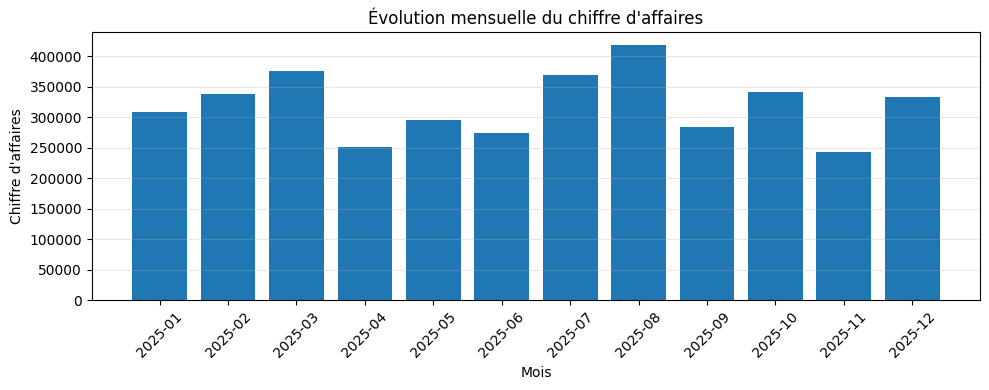

In [0]:
%python
import matplotlib.pyplot as plt

# Requête SQL
ca_mensuel = spark.sql(f"""
SELECT
    d.year,
    d.month,
    SUM(f.amount) AS chiffre_affaires
FROM {FACT} AS f
JOIN {CALENDAR} AS d ON f.date_key = d.date_key
GROUP BY d.year, d.month
ORDER BY d.year, d.month
""")

# Conversion en pandas (12 lignes seulement)
df = ca_mensuel.toPandas()
df["periode"] = (
    df["year"].astype(str) + "-"
    + df["month"].astype(str).str.zfill(2)
)

# Graphique
fig, ax = plt.subplots(figsize=(10, 4))

ax.bar(df["periode"], df["chiffre_affaires"])

ax.set_title("Évolution mensuelle du chiffre d'affaires")
ax.set_xlabel("Mois")
ax.set_ylabel("Chiffre d'affaires")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**Question 3 — Quels lieux génèrent le plus de chiffre d'affaires ?**

Le lieu est celui de **l'utilisation ou de la livraison du service**,
et non nécessairement la cabine du passager.
**Petite manipulation :** remplacer `LIMIT 5` par `LIMIT 10`.

In [0]:
display(spark.sql(f"""
SELECT
    l.location_name,
    l.location_deck,
    SUM(f.amount) AS chiffre_affaires
FROM {FACT} AS f
JOIN {DIM_LOCATION} AS l ON f.location_key = l.location_key
GROUP BY l.location_name, l.location_deck
ORDER BY chiffre_affaires DESC
LIMIT 5
"""))

location_name,location_deck,chiffre_affaires
Food Court Promenade,D,980098.00
Food Court Atrium,C,939711.00
Spa Panorama,A,615695.00
Spa Central,B,607291.00
Cabines pont F - Tribord,F,153135.00


**Question 4 — Quelle est la dépense moyenne par passager selon
la planète d'origine et le statut VIP ?**

**Point important :** 1 832 passagers n'ont **aucune dépense positive**
dans les trois services. Un `INNER JOIN` depuis la table de faits les
écarterait ; pour une **moyenne par passager**, il faut partir de
`dim_passenger` et utiliser un `LEFT JOIN`.

*Bonus* : essayer de ne regrouper que par `home_planet` et discuter
l'effet sur la moyenne. Ne pas inférer de causalité à partir de ces données.

In [0]:
display(spark.sql(f"""
WITH depenses_par_passager AS (
    SELECT
        p.passenger_key,
        p.home_planet,
        p.is_vip,
        COALESCE(SUM(f.amount), CAST(0 AS DECIMAL(16,2))) AS total_depenses
    FROM {DIM_PASSENGER} AS p
    LEFT JOIN {FACT} AS f ON p.passenger_key = f.passenger_key
    GROUP BY p.passenger_key, p.home_planet, p.is_vip
)
SELECT
    home_planet,
    is_vip,
    COUNT(*) AS passagers,
    SUM(CASE WHEN total_depenses > 0 THEN 1 ELSE 0 END) AS passagers_actifs,
    ROUND(AVG(total_depenses), 2) AS depense_moyenne_par_passager
FROM depenses_par_passager
GROUP BY home_planet, is_vip
ORDER BY home_planet, is_vip
"""))

home_planet,is_vip,passagers,passagers_actifs,depense_moyenne_par_passager
Earth,false,2227,1246,397.49
Earth,true,6,5,1234.83
Europa,false,891,455,2435.70
Europa,true,70,56,3785.31
Mars,false,780,384,615.87
Mars,true,26,22,896.35


## 6. Vérifier le modèle

**Exercice 3 :** que vérifier avant d'utiliser ces résultats dans un
tableau de bord ?

- Une dimension : **une clé métier unique**.
- La table de faits : **une transaction = une ligne**.
- Les clés de fait : **toutes résolues**.
- Les montants : **les mêmes totaux qu'en Silver**, sans perte ni doublon.

Le contrôle ci-dessous va plus loin que la seule somme globale :
il compare les montants **par passager et par service**, y compris
lorsque le montant attendu est nul.

In [0]:
passagers_silver = spark.table(PASSENGERS)
montants_attendus = (passagers_silver
    .select(
        F.col("PassengerId").alias("passenger_id"),
        F.create_map(
            F.lit("ROOM"), F.coalesce(F.col("RoomService").cast("decimal(14,2)"), F.lit(0).cast("decimal(14,2)")),
            F.lit("FOOD"), F.coalesce(F.col("FoodCourt").cast("decimal(14,2)"), F.lit(0).cast("decimal(14,2)")),
            F.lit("SPA"), F.coalesce(F.col("Spa").cast("decimal(14,2)"), F.lit(0).cast("decimal(14,2)")),
        ).alias("par_service"),
    )
    .select("passenger_id", F.explode("par_service").alias("service_code", "attendu")))

montants_observes = (spark.table(SILVER)
    .withColumnRenamed("PassengerId", "passenger_id")
    .groupBy("passenger_id", "service_code")
    .agg(F.sum("amount").alias("observe")))

anomalies = (montants_attendus
    .join(montants_observes, ["passenger_id", "service_code"], "left")
    .withColumn("observe", F.coalesce(F.col("observe"), F.lit(0).cast("decimal(14,2)")))
    .filter(F.col("attendu") != F.col("observe")))

assert anomalies.count() == 0, "Écart entre les totaux Silver TP3 et les transactions"

bilan = spark.sql(f"""
SELECT COUNT(*) AS transactions,
       COUNT(DISTINCT transaction_id) AS transactions_uniques,
       SUM(amount) AS montant_total
FROM {FACT}
""").first()
assert bilan["transactions"] == 9260
assert bilan["transactions_uniques"] == 9260
assert bilan["montant_total"] == 3831489

# Vérifier qu'aucune dimension ne démultiplie les transactions.
for table, natural_key in (
    (DIM_PASSENGER, "passenger_id"),
    (DIM_SERVICE, "service_code"),
    (DIM_LOCATION, "location_code"),
    (CALENDAR, "date_key"),
):
    d = spark.table(table)
    assert d.count() == d.select(natural_key).distinct().count(), f"Clé non unique : {table}"

print("Contrôles OK : 4 000 passagers ; 9 260 transactions ; 3 831 489 crédits ; aucun écart.")

Contrôles OK : 4 000 passagers ; 9 260 transactions ; 3 831 489 crédits ; aucun écart.


## Bilan

**À retenir :**
1. Un **grain précis** détermine ce qu'enregistre la table de faits.
2. Une table de faits contient des **mesures** et des clés vers des **dimensions**.
3. Les dimensions permettent de filtrer et regrouper les faits pour répondre
   aux questions métier.
4. Une dimension calendrier existante peut être **réutilisée** dans plusieurs
   modèles (dimension conforme) ; cela ne signifie pas qu'il faut joindre
   directement les faits de l'énergie avec ceux des dépenses.
5. **Modèle correct ≠ observations réelles** : les dates et lieux ici sont
   simulés. Une valeur imputée à 0 au TP1 reste une estimation.

**Non traités volontairement :** schéma en flocon, SCD Type 2 et pipelines
Lakeflow. Ils appartiennent au cours théorique ou à un approfondissement.

---
### Repères perso

**Données attendues (CSV distribué) :**
- `dim_passenger` : **4 000 lignes**, dont **1 832 passagers** sans montant
  strictement positif dans les trois services ;
- `dim_service` : **3 lignes** (`ROOM`, `FOOD`, `SPA`) ;
- `dim_location` : **18 lieux présents dans les transactions** ;
- `dim_calendar_2025` : **365 dates** ;
- `fact_service_usage` : **9 260 transactions**, toutes avec des clés résolues ;
- montant global : **3 831 489 crédits**, dont `ROOM` **688 694**,
  `FOOD` **1 919 809**, `SPA` **1 222 986** ;
- rapprochement **par passager et service** : aucun écart.

**Réponses / points de discussion :**
- Q1 : `FOOD` arrive en tête en chiffre d'affaires ; nombre d'opérations,
  nombre de consommateurs et chiffre d'affaires sont différents.
- Q2 / Q3 : résultats entièrement **synthétiques** pour les dates et lieux ;
  ils n'autorisent pas d'interprétation réelle de la saisonnalité ou de
  l'attractivité des zones.
- Q4 : utiliser `LEFT JOIN` depuis `dim_passenger` pour inclure les
  passagers sans transaction ; ce n'est pas la moyenne des seuls clients actifs.
- `RoomService_missing` = **280** imputations à zéro au TP3 ; un zéro
  imputé ne prouve pas qu'aucune consommation n'a eu lieu.
- Une dimension peut être **dénormalisée** et rassembler plusieurs
  attributs ; ne pas isoler `VIP`, `HomePlanet`, `Destination` par principe.
- L'identifiant `transaction_id` est conservé dans les faits comme
  identifiant de l'opération (*degenerate dimension*).
- `ROW_NUMBER` est déterministe pour la photographie fixe du TP ; une
  réintégration incrémentale ou une SCD2 exigerait une autre gestion des clés.

**Pour tenir en une heure :** exécuter les créations SQL en démonstration
guidée. Faire écrire / compléter surtout les requêtes d'analyse. La
question 4 peut devenir un bonus pour les groupes moins rapides.

**Validation d'environnement :** cette correction a été contrôlée
hors Databricks sur les fichiers locaux ; exécuter une fois dans un
workspace Free Edition avant de la distribuer aux étudiants.